# Modelo v2 — DenseNet121 optimizado (aumento + scheduler + early stopping)
Framework: **PyTorch** (torchvision trae DenseNet121 listo). Si se define otro framework, este notebook se porta.

## Bloque 0 — Entorno: Drive, GPU, rutas e hiperparámetros

In [4]:
# Bloque 0.0 — Recuperar corrida existente (SOLO si se perdió la sesión de Colab)
from pathlib import Path  # aquí se arma la ruta de la corrida a recuperar
CARPETA_CORRIDA = Path('/content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20260924_064905_auc9854')
RUTA_MEJOR = CARPETA_CORRIDA / 'best.pth'  # el mejor de ESA corrida
print('Corrida a recuperar:', CARPETA_CORRIDA)
print('Existe carpeta:', CARPETA_CORRIDA.exists(), '| Existe best.pth:', RUTA_MEJOR.exists())


Corrida a recuperar: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20260924_064905_auc9854
Existe carpeta: True | Existe best.pth: True


In [5]:
# Bloque 0.1 — Montar Drive, imports, semilla y GPU
# Imports base (Drive, azar, torch, GPU): estado global que todo lo demás necesita.
# Lo específico (pandas, rutas, hiperparámetros...) se define en el bloque que lo usa.
from google.colab import drive
drive.mount('/content/drive')

import random
import numpy as np  # lo necesita np.random.seed de abajo

import torch

# Semilla fija: mismos números aleatorios en cada corrida (resultado repetible).
# Va aquí y no en otro bloque porque es ESTADO GLOBAL: rige el azar de TODO
# lo que viene después (mezclado de lotes en 1.3/3.2, pesos iniciales en 2.1).
# Moverla más abajo rompería la repetibilidad en silencio.
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

# GPU: el entrenamiento corre ahí (mucho más rápido que CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('GPU disponible:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('Nombre GPU:', torch.cuda.get_device_name(0))
else:
    print('AVISO: sin GPU el entrenamiento será muy lento. Actívala en Entorno > Cambiar tipo de ejecución.')
print('Dispositivo de trabajo:', device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.11.0+cu130
GPU disponible: True
Nombre GPU: Tesla T4
Dispositivo de trabajo: cuda


In [6]:
# Bloque 0.2 — Traer el ZIP del Drive al disco local
# Se copia 1 solo archivo seguido (rápido). Si ya está con igual tamaño, se reutiliza.
import shutil
import time
from pathlib import Path  # rutas locales y del Drive
from tqdm import tqdm  # barra de progreso (Colab ya lo trae instalado)

DRIVE_DATASETS = Path('/content/drive/MyDrive/TESIS/DATASETS')

# El ZIP en Drive (nombre fijo, tal como se descargó de Kaggle)
ZIP_ORIGEN = DRIVE_DATASETS / 'rsna-pneumonia-detection-challenge.zip'
print(f'ZIP en Drive: {ZIP_ORIGEN.name} ({ZIP_ORIGEN.stat().st_size / 1e9:.2f} GB)')


def copiar_con_barra(origen, destino):
    """Copia 1 archivo grande mostrando barra, velocidad y tiempo estimado."""
    destino.parent.mkdir(parents=True, exist_ok=True)
    total = origen.stat().st_size
    t0 = time.time()
    with open(origen, 'rb') as f0, open(destino, 'wb') as f1, tqdm(total=total, unit='B', unit_scale=True, desc=f'   - {origen.name}') as barra:
        while True:
            trozo = f0.read(8 * 1024 * 1024)
            if not trozo:
                break
            f1.write(trozo)
            barra.update(len(trozo))
    shutil.copystat(origen, destino)
    print(f'   - copiado en {time.time() - t0:.0f} s.')


ZIP_LOCAL = Path('/content') / ZIP_ORIGEN.name
if ZIP_LOCAL.exists() and ZIP_LOCAL.stat().st_size == ZIP_ORIGEN.stat().st_size:
    print('ZIP ya está en local, se reutiliza.')
else:
    copiar_con_barra(ZIP_ORIGEN, ZIP_LOCAL)

ZIP en Drive: rsna-pneumonia-detection-challenge.zip (3.93 GB)
ZIP ya está en local, se reutiliza.


In [7]:
# Bloque 0.3 — Descomprimir en local y traer los CSV de splits
# El ZIP trae su propia carpeta (rsna-pneumonia-detection-challenge/); se usa tal cual.
# Los splits v2 ya vienen filtrados del Drive (test_v2.ipynb); aquí solo se copian.
# v1 queda intacto: este notebook NUNCA lee ni escribe DATASETS/splits (solo v2).
t0 = time.time()  # inicio local: el t0 del 0.2 vive solo dentro de la función
print('Descomprimiendo/actualizando en local (extrae solo lo que falte)...')
!unzip -uq '{ZIP_LOCAL}' -d '/content'
print(f'Listo en {time.time() - t0:.0f} s.')
FUENTE_IMGS = Path('/content/rsna-pneumonia-detection-challenge/stage_2_train_images')
if not FUENTE_IMGS.exists():
    # el ZIP trajo otra estructura: se ubica donde realmente quedó
    _cands = [p for p in Path('/content').rglob('stage_2_train_images') if p.is_dir()]
    assert len(_cands) > 0, 'No se halló stage_2_train_images tras descomprimir'
    FUENTE_IMGS = _cands[0]
print(f'DICOMs locales: {len(list(FUENTE_IMGS.glob("*.dcm"))):,} en {FUENTE_IMGS}')
print(f'DICOMs locales: {len(list(FUENTE_IMGS.glob("*.dcm"))):,}')

CARPETA_SPLITS = Path('/content/splits')  # aquí se copian los 3 CSV
CARPETA_SPLITS.mkdir(parents=True, exist_ok=True)
for _n in ['train.csv', 'val.csv', 'test.csv']:
    _origen = DRIVE_DATASETS / 'v2' / 'splits' / _n
    assert _origen.exists(), f'Falta {_n} en DATASETS/v2/splits (corre test_v2.ipynb primero)'
    shutil.copy2(_origen, CARPETA_SPLITS / _n)
print('Splits en:', CARPETA_SPLITS)

Descomprimiendo/actualizando en local (extrae solo lo que falte)...
Listo en 47 s.
DICOMs locales: 26,684 en /content/stage_2_train_images
DICOMs locales: 26,684
Splits en: /content/splits


In [8]:
# Bloque 0.4 — Ruta de salida (los .npy que generará el 0.6)
CARPETA_NPY = Path('/content/dataset_filtrado')  # train/ val/ test/ con .npy
print('NPY:', CARPETA_NPY.exists(), '(False = aún no se corre el 0.6)')
print('Todo el trabajo corre en /content.')

NPY: False (False = aún no se corre el 0.6)
Todo el trabajo corre en /content.


In [9]:
# Bloque 0.5 — Funciones de transformación (solo se definen aquí, no procesan nada)
# Convierten 1 DICOM en 1 array (3,224,224) normalizado, en 4 pasos:
#   1. leer_dicom_como_gris: .dcm -> gris 0-255
#   2. redimensionar: 1024 -> 224
#   3. gris_a_rgb: 1 canal -> 3 canales
#   4. normalizar_imagenet: 0-255 -> escala ImageNet
# (Idénticas a las del Bloque 2 de test.ipynb; el 0.6 las aplica a todo.)

from PIL import Image  # aquí se redimensiona

# Media y desviación de ImageNet (las que espera DenseNet121 preentrenado).
# Se definen aquí porque solo se usan al normalizar.
MEDIA_IMAGENET = np.array([0.485, 0.456, 0.406], dtype=np.float32)
DESV_IMAGENET = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def leer_dicom_como_gris(ruta_dicom):
    """Paso 1: lee un .dcm y devuelve array uint8 de 0-255 en escala de grises."""
    import pydicom
    ds = pydicom.dcmread(str(ruta_dicom))
    img = ds.pixel_array
    if str(ds.get('PhotometricInterpretation', '')) == 'MONOCHROME1':
        img = 255 - img  # fondo negro -> fondo blanco (estándar radiológico)
    img = img.astype(np.float32)
    if img.max() > 255:  # por si algún DICOM trae 16 bits
        img = img / img.max() * 255.0
    return np.clip(img, 0, 255).astype(np.uint8)


def redimensionar(imagen_gris, tamano=224):
    """Paso 2: achica la imagen al tamaño que pide DenseNet121 (224x224)."""
    return np.array(Image.fromarray(imagen_gris).resize((tamano, tamano), Image.BILINEAR))


def gris_a_rgb(imagen_gris):
    """Paso 3: copia el gris en 3 canales RGB (0-1)."""
    rgb = np.stack([imagen_gris, imagen_gris, imagen_gris], axis=0)
    return rgb.astype(np.float32) / 255.0


def normalizar_imagenet(imagen_rgb):
    """Paso 4: ajusta los valores con media/desviación de ImageNet."""
    return (imagen_rgb - MEDIA_IMAGENET[:, None, None]) / DESV_IMAGENET[:, None, None]


def preprocesar_imagen(ruta_dicom, tamano=224):
    """Aplica los 4 pasos en orden: DICOM -> array (3, tamano, tamano) normalizado."""
    gris = leer_dicom_como_gris(ruta_dicom)
    gris_224 = redimensionar(gris, tamano)
    rgb = gris_a_rgb(gris_224)
    return normalizar_imagenet(rgb)


print('Funciones listas: leer_dicom_como_gris, redimensionar, gris_a_rgb, normalizar_imagenet, preprocesar_imagen.')

Funciones listas: leer_dicom_como_gris, redimensionar, gris_a_rgb, normalizar_imagenet, preprocesar_imagen.


In [10]:
# Bloque 0.6 — Generar los .npy en el disco local
# Recorre los 3 CSV y transforma SOLO lo que dicen (14,013 imágenes, no todo el ZIP).
# Muestra barra por split; si se cortó antes, continúa donde quedó (valida contenido, no solo existencia).
!pip install -q pydicom  # se instala aquí porque solo este bloque lee DICOMs
import pandas as pd  # aquí se leen los CSV de splits

def archivo_valido(ruta):
    """True si el .npy existe, pesa >0 y abre con forma (3,224,224)."""
    try:
        if not ruta.exists() or ruta.stat().st_size == 0:
            return False
        return np.load(ruta).shape == (3, 224, 224)
    except Exception:
        return False


def exportar_local():
    """Genera los .npy en disco local; regenera los vacíos o corruptos."""
    from tqdm import tqdm  # barra de progreso (Colab ya lo trae instalado)
    for split in ['train', 'val', 'test']:
        df_split = pd.read_csv(CARPETA_SPLITS / f'{split}.csv')
        carpeta = CARPETA_NPY / split
        carpeta.mkdir(parents=True, exist_ok=True)
        # Verifica uno por uno: una interrupción deja archivos vacíos a medias
        pendientes = []
        for _, fila in tqdm(df_split.iterrows(), total=len(df_split), desc=f'   - verificar {split}'):
            if not archivo_valido(carpeta / f"{fila['patientId']}.npy"):
                pendientes.append(fila)
        print(f'   - {split}: {len(df_split):,} total | válidos {len(df_split) - len(pendientes):,} | a generar {len(pendientes):,}')
        for fila in tqdm(pendientes, desc=f'   - generar {split}'):
            arr = preprocesar_imagen(FUENTE_IMGS / f"{fila['patientId']}.dcm")
            np.save(carpeta / f"{fila['patientId']}.npy", arr)
        print(f'   - {split} OK en {carpeta}')


# Genera los .npy locales (solo transforma lo que dicen los CSV de splits).
exportar_local()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 40.2 MB/s eta 0:00:00


   - verificar train: 100%|██████████| 9807/9807 [00:01<00:00, 9109.16it/s] 


   - train: 9,807 total | válidos 0 | a generar 9,807


   - generar train: 100%|██████████| 9807/9807 [02:19<00:00, 70.50it/s]


   - train OK en /content/dataset_filtrado/train


   - verificar val: 100%|██████████| 2102/2102 [00:00<00:00, 7831.69it/s]


... (3 outputs left out)

   - verificar test: 100%|██████████| 2104/2104 [00:00<00:00, 9163.67it/s]


   - test: 2,104 total | válidos 0 | a generar 2,104


   - generar test: 100%|██████████| 2104/2104 [00:28<00:00, 74.47it/s]

   - test OK en /content/dataset_filtrado/test


## Bloque 1 — Datos: CSV + .npy → cargadores

In [11]:
# Bloque 1.1 — Cargar los 3 CSV y verificar que todo calce
df_train = pd.read_csv(CARPETA_SPLITS / 'train.csv')
df_val = pd.read_csv(CARPETA_SPLITS / 'val.csv')
df_test = pd.read_csv(CARPETA_SPLITS / 'test.csv')

for nombre, df in [('train', df_train), ('val', df_val), ('test', df_test)]:
    print(f'{nombre}: {len(df):,} filas | neumonía={df["etiqueta"].mean():.2%}')

# Verificación: cada fila del CSV debe tener su .npy en la carpeta que le toca
for nombre, df in [('train', df_train), ('val', df_val), ('test', df_test)]:
    n_npy = len(list((CARPETA_NPY / nombre).glob('*.npy')))
    print(f'{nombre}: {n_npy:,} archivos .npy')
    assert n_npy == len(df), f'Faltan .npy en {nombre} (corre el Bloque 0.6)'
print('Verificación OK: todo CSV tiene sus imágenes.')

train: 9,807 filas | neumonía=40.15%
val: 2,102 filas | neumonía=40.15%
test: 2,104 filas | neumonía=40.16%
train: 9,807 archivos .npy
val: 2,102 archivos .npy
test: 2,104 archivos .npy
Verificación OK: todo CSV tiene sus imágenes.


In [12]:
# Bloque 1.2 — Lector de datos: convierte cada fila del CSV en (imagen, etiqueta)
# El modelo no come archivos: esta clase carga el .npy y lo entrega como tensor.
# Novedad v2: el train aplica aumento (flip + rotación leve) en memoria, en cada época.
# Val/test van sin aumento (medición limpia). No se guardan imágenes aumentadas.
from torch.utils.data import Dataset, DataLoader  # aquí se define el lector que los usa
from torchvision import transforms as T  # aquí vive el aumento (solo train)

AUMENTO_TRAIN = T.Compose([  # geométrico leve: no inventa anatomía, solo varía la vista
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=8, interpolation=T.InterpolationMode.BILINEAR),
])


class RadioDataset(Dataset):
    """Lee .npy (3,224,224) + etiqueta (0/1) a partir de un CSV de split."""
    def __init__(self, df, carpeta_npy, aumentar=False):
        self.df = df.reset_index(drop=True)
        self.carpeta_npy = Path(carpeta_npy)
        self.aumentar = aumentar  # True solo en train

    def __len__(self):
        return len(self.df)  # cuántas imágenes hay

    def __getitem__(self, i):
        # i = número de fila: se busca su .npy y su etiqueta
        fila = self.df.iloc[i]
        imagen = torch.from_numpy(np.load(self.carpeta_npy / f"{fila['patientId']}.npy"))
        if self.aumentar:
            imagen = AUMENTO_TRAIN(imagen)
        etiqueta = torch.tensor(float(fila['etiqueta']))
        return imagen, etiqueta

print('Clase RadioDataset definida (aún no lee nada, solo es el molde).')
print('Aumento train:', AUMENTO_TRAIN)


Clase RadioDataset definida (aún no lee nada, solo es el molde).
Aumento train: Compose(
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-8.0, 8.0], interpolation=bilinear, expand=False, fill=0)
)


In [13]:
# Bloque 1.3 — Armar los 3 cargadores y probar con un lote
# train se mezcla (shuffle) en cada época; val/test van en orden fijo.
BATCH = 32       # imágenes por lote: 32 cabe bien en la GPU gratis de Colab
TRABAJADORES = 2 # hilos que cargan imágenes mientras la GPU entrena
ds_train = RadioDataset(df_train, CARPETA_NPY / 'train', aumentar=True)  # v2: aumento aquí
ds_val = RadioDataset(df_val, CARPETA_NPY / 'val')
ds_test = RadioDataset(df_test, CARPETA_NPY / 'test')

en_gpu = (device.type == 'cuda')
cargar_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True, num_workers=TRABAJADORES, pin_memory=en_gpu)
cargar_val = DataLoader(ds_val, batch_size=BATCH, shuffle=False, num_workers=TRABAJADORES, pin_memory=en_gpu)
cargar_test = DataLoader(ds_test, batch_size=BATCH, shuffle=False, num_workers=TRABAJADORES, pin_memory=en_gpu)

# Prueba: un lote del train. Forma esperada: (32 imágenes, 3 canales, 224, 224)
imagenes, etiquetas = next(iter(cargar_train))
print('Lote imágenes:', tuple(imagenes.shape), '| Lote etiquetas:', tuple(etiquetas.shape))
print('Etiquetas del lote:', etiquetas.int().tolist())
assert tuple(imagenes.shape[1:]) == (3, 224, 224), 'Forma inesperada en las imágenes'
print(f'Lotes por época -> train: {len(cargar_train)}, val: {len(cargar_val)}, test: {len(cargar_test)}')

Lote imágenes: (32, 3, 224, 224) | Lote etiquetas: (32,)
Etiquetas del lote: [0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1]
Lotes por época -> train: 307, val: 66, test: 66


## Bloque 2 — Modelo: DenseNet121 preentrenado + regla de aprendizaje

In [14]:
# Bloque 2.1 — Modelo v1: DenseNet121 preentrenado, adaptado a 1 salida
# Transfer learning en simple: el modelo ya sabe "ver" (aprendió con ImageNet)
# y solo se le cambia la última capa para que responda sí/no neumonía.
# (Los pesos se descargan solos la primera vez, ~30 MB.)
from torchvision import models  # aquí se crea el DenseNet121
import torch.nn as nn  # aquí se reemplaza su última capa
modelo = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)

# La última capa original responde 1000 clases de fotos; se reemplaza por 1 neurona
n_entradas = modelo.classifier.in_features
modelo.classifier = nn.Linear(n_entradas, 1)
modelo = modelo.to(device)

# Cuántos números va a ajustar el entrenamiento (parámetros entrenables)
n_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
print(f'DenseNet121 listo en {device} | parámetros a entrenar: {n_params:,}')
print('Última capa:', modelo.classifier)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 102MB/s]


DenseNet121 listo en cuda | parámetros a entrenar: 6,954,881
Última capa: Linear(in_features=1024, out_features=1, bias=True)


In [15]:
# Bloque 2.2 — Regla de aprendizaje: pérdida + optimizador
# Hay más "sin neumonía" que "con": pos_weight equilibra para que el modelo
# no aprenda el truco de responder siempre 0. Se calcula solo desde el train.
LR = 1e-4  # paso de aprendizaje: chico porque el modelo ya viene preentrenado
n_pos = int(df_train['etiqueta'].sum())
n_neg = len(df_train) - n_pos
peso_pos = torch.tensor([n_neg / n_pos], device=device)
print(f'Train: {n_pos:,} con neumonía / {n_neg:,} sin | peso positivo = {peso_pos.item():.3f}')

# Pérdida: castiga qué tan lejos quedó la respuesta de la etiqueta real
criterio = nn.BCEWithLogitsLoss(pos_weight=peso_pos)
# Optimizador: ajusta los parámetros un poquito tras cada lote (paso = LR)
optimizador = torch.optim.Adam(modelo.parameters(), lr=LR)
# Nota v2: se mantiene pos_weight (comparable con v1); focal loss queda como experimento futuro.
print('Pérdida: BCEWithLogitsLoss | Optimizador: Adam con LR =', LR)

Train: 3,938 con neumonía / 5,869 sin | peso positivo = 1.490
Pérdida: BCEWithLogitsLoss | Optimizador: Adam con LR = 0.0001


## Bloque 3 — Entrenamiento (guarda el mejor según val)

In [16]:
# Bloque 3.1 — Funciones de entrenamiento y evaluación (solo se definen aquí)
from sklearn.metrics import roc_auc_score
UMBRAL = 0.5  # probabilidad >= 0.5 cuenta como con neumonía (1). Lo usan evaluar (3.1), test (4.1) y casos (5.3).
from tqdm import tqdm  # barra por lote (Colab ya lo trae instalado)

def entrenar_epoca(modelo, cargador):
    """Una vuelta completa al train: predice, mide error, corrige. Devuelve pérdida media."""
    modelo.train()
    perdidas = []
    for imagenes, etiquetas in cargador:
        imagenes, etiquetas = imagenes.to(device), etiquetas.to(device)
        optimizador.zero_grad()                # borra correcciones anteriores
        salidas = modelo(imagenes).squeeze(1)  # respuesta: 1 número por imagen
        perdida = criterio(salidas, etiquetas) # qué tan mal respondió
        perdida.backward()                     # calcula cómo corregir
        optimizador.step()                     # aplica la corrección
        perdidas.append(perdida.item())
    return float(np.mean(perdidas))


@torch.no_grad()  # aquí no se corrige nada, solo se mide (más rápido)
def evaluar(modelo, cargador):
    """Pasa val/test SIN corregir. Devuelve pérdida, exactitud y AUC."""
    modelo.eval()
    perdidas, todas_prob, todas_et = [], [], []
    for imagenes, etiquetas in cargador:
        imagenes, etiquetas = imagenes.to(device), etiquetas.to(device)
        salidas = modelo(imagenes).squeeze(1)
        perdidas.append(criterio(salidas, etiquetas).item())
        todas_prob.extend(torch.sigmoid(salidas).cpu().tolist())  # a probabilidad 0-1
        todas_et.extend(etiquetas.cpu().tolist())
    todas_prob = np.array(todas_prob)
    todas_et = np.array(todas_et)
    pred = (todas_prob >= UMBRAL).astype(int)
    acc = float((pred == todas_et).mean())
    auc = float(roc_auc_score(todas_et, todas_prob))
    return float(np.mean(perdidas)), acc, auc

print('Funciones entrenar_epoca y evaluar definidas.')

Funciones entrenar_epoca y evaluar definidas.


In [17]:
# Bloque 3.2 — Entrenamiento optimizado (scheduler + early stopping)
# Novedades v2 vs v1: (1) el train ya trae aumento (1.3), (2) el LR baja solo si el
# AUC val se estanca, (3) se para antes si no mejora. Se sigue guardando el mejor por AUC val.
EPOCAS = 15  # máximo: con early stopping suele parar antes (en v1 lo mejor fue época 2)
PACIENCIA = 3  # épocas seguidas sin mejorar AUC val antes de parar
CARPETA_MODELOS = Path('/content/drive/MyDrive/TESIS/MODELOS')  # aquí se guarda todo lo entrenado
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)
# Cada época imprime su duración y cuánto falta aprox.
import time
# Cada corrida tiene su ID (fecha-hora): ningún archivo se sobrescribe entre corridas.
from datetime import datetime
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S')
from torch.optim.lr_scheduler import ReduceLROnPlateau  # aquí se crea el scheduler
scheduler = ReduceLROnPlateau(optimizador, mode='max', factor=0.5, patience=2)
mejor_auc = 0.0  # se compara solo dentro de ESTA corrida
sin_mejora = 0  # contador de early stopping (solo dentro de ESTA corrida)
CARPETA_CORRIDA = CARPETA_MODELOS / f'densenet121_v2_{RUN_ID}'
CARPETA_CORRIDA.mkdir(parents=True, exist_ok=True)
RUTA_MEJOR = CARPETA_CORRIDA / 'best.pth'  # el mejor DE ESTA corrida
historial = []  # una fila por época: train_loss, val_loss, val_acc, val_auc, lr

for epoca in range(1, EPOCAS + 1):
    t_ep = time.time()
    p_train = entrenar_epoca(modelo, cargar_train)
    p_val, acc_val, auc_val = evaluar(modelo, cargar_val)
    lr_ahora = float(optimizador.param_groups[0]['lr'])  # LR usado en ESTA época
    historial.append({'epoca': epoca, 'train_loss': p_train, 'val_loss': p_val,
                      'val_acc': acc_val, 'val_auc': auc_val, 'lr': lr_ahora})
    marca = ''
    if auc_val > mejor_auc:
        mejor_auc = auc_val
        torch.save(modelo.state_dict(), RUTA_MEJOR)
        marca = '  <-- GUARDADO (mejor AUC val)'
        sin_mejora = 0
    else:
        sin_mejora += 1
    scheduler.step(auc_val)  # si el AUC val se estanca, el próximo LR baja a la mitad
    dur = time.time() - t_ep
    eta_min = dur * (EPOCAS - epoca) / 60
    print(f'Época {epoca}/{EPOCAS} | train_loss={p_train:.4f} | val_loss={p_val:.4f} | val_acc={acc_val:.4f} | val_auc={auc_val:.4f} | lr={lr_ahora:.0e} | {dur:.0f}s (~faltan {eta_min:.0f} min){marca}')
    if sin_mejora >= PACIENCIA:
        print(f'Parada temprana en época {epoca}: {PACIENCIA} épocas sin mejorar AUC val.')
        break

pd.DataFrame(historial).to_csv(CARPETA_CORRIDA / 'historial.csv', index=False)
print(f'\nMejor AUC val: {mejor_auc:.4f} | Modelo en: {RUTA_MEJOR}')
# La carpeta final lleva fecha + mejor AUC (ej: ..._20260909_153015_auc9865)
CARPETA_FINAL = CARPETA_MODELOS / f"densenet121_v2_{RUN_ID}_auc{str(round(mejor_auc, 4)).replace('0.', '')}"
CARPETA_CORRIDA.rename(CARPETA_FINAL)
CARPETA_CORRIDA = CARPETA_FINAL
RUTA_MEJOR = CARPETA_CORRIDA / 'best.pth'
print(f'Carpeta de la corrida: {CARPETA_CORRIDA}')


Época 1/15 | train_loss=0.2599 | val_loss=0.2647 | val_acc=0.9334 | val_auc=0.9807 | lr=1e-04 | 119s (~faltan 28 min)  <-- GUARDADO (mejor AUC val)
Época 2/15 | train_loss=0.1889 | val_loss=0.2032 | val_acc=0.9372 | val_auc=0.9818 | lr=1e-04 | 113s (~faltan 25 min)  <-- GUARDADO (mejor AUC val)
Época 3/15 | train_loss=0.1566 | val_loss=0.1866 | val_acc=0.9458 | val_auc=0.9836 | lr=1e-04 | 113s (~faltan 23 min)  <-- GUARDADO (mejor AUC val)
Época 4/15 | train_loss=0.1424 | val_loss=0.2022 | val_acc=0.9491 | val_auc=0.9834 | lr=1e-04 | 113s (~faltan 21 min)
Época 5/15 | train_loss=0.1309 | val_loss=0.2088 | val_acc=0.9500 | val_auc=0.9834 | lr=1e-04 | 113s (~faltan 19 min)
Época 6/15 | train_loss=0.1019 | val_loss=0.2508 | val_acc=0.9529 | val_auc=0.9852 | lr=1e-04 | 113s (~faltan 17 min)  <-- GUARDADO (mejor AUC val)
Época 7/15 | train_loss=0.0994 | val_loss=0.2284 | val_acc=0.9486 | val_auc=0.9835 | lr=1e-04 | 113s (~faltan 15 min)
Época 8/15 | train_loss=0.0856 | val_loss=0.2207 | val

In [18]:
# Bloque 3.3 — Ver el historial época por época
df_hist = pd.DataFrame(historial)
print(df_hist.to_string(index=False))

 epoca  train_loss  val_loss  val_acc  val_auc     lr
     1    0.259895  0.264678 0.933397 0.980744 0.0001
     2    0.188887  0.203165 0.937203 0.981846 0.0001
     3    0.156592  0.186619 0.945766 0.983605 0.0001
     4    0.142363  0.202191 0.949096 0.983409 0.0001
     5    0.130876  0.208845 0.950048 0.983351 0.0001
     6    0.101911  0.250794 0.952902 0.985176 0.0001
     7    0.099428  0.228396 0.948620 0.983542 0.0001
     8    0.085623  0.220683 0.947193 0.985999 0.0001
     9    0.075704  0.207340 0.942912 0.984731 0.0001
    10    0.060776  0.248330 0.942436 0.980283 0.0001
    11    0.053914  0.364366 0.935300 0.976020 0.0001


## Bloque 4 — Evaluación FINAL en test (una sola vez, al final)

In [19]:
# Bloque 4.1 — Medir el mejor modelo con datos que nunca vio entrenando
# Métricas de tesis: exactitud, AUC, sensibilidad, especificidad + matriz de confusión.
from sklearn.metrics import confusion_matrix, roc_auc_score
from tqdm import tqdm  # barra por lote (Colab ya lo trae instalado)
import time as _time
_t0 = _time.time()

# Evalúa el mejor DE ESTA corrida. Para otra versión, cambia RUTA_MEJOR por su archivo.
modelo.load_state_dict(torch.load(RUTA_MEJOR, map_location=device))
modelo.eval()
probs, reales = [], []
with torch.no_grad():
    for imagenes, etiquetas in tqdm(cargar_test, desc='   - lotes test', leave=False):
        salidas = modelo(imagenes.to(device)).squeeze(1)
        probs.extend(torch.sigmoid(salidas).cpu().tolist())
        reales.extend(etiquetas.tolist())
probs = np.array(probs)
reales = np.array(reales)
pred = (probs >= UMBRAL).astype(int)

acc = float((pred == reales).mean())
auc = float(roc_auc_score(reales, probs))
tn, fp, fn, tp = confusion_matrix(reales, pred).ravel()
sens = float(tp / (tp + fn))  # sensibilidad: de los enfermos, cuántos detectó
esp = float(tn / (tn + fp))   # especificidad: de los sanos, cuántos acertó

print(f'TEST (n={len(reales):,}) | exactitud={acc:.4f} | AUC={auc:.4f} | medido en {_time.time() - _t0:.0f} s')
print(f'Sensibilidad={sens:.4f} | Especificidad={esp:.4f} (umbral={UMBRAL})')
print('Matriz de confusión [filas=real, columnas=predicho]:')
print('                 pred 0     pred 1')
print(f'  real 0 (sano):  {tn:>6,}  {fp:>9,}')
print(f'  real 1 (neum):  {fn:>6,}  {tp:>9,}')

TEST (n=2,104) | exactitud=0.9582 | AUC=0.9883 | medido en 9 s
Sensibilidad=0.9172 | Especificidad=0.9857 (umbral=0.5)
Matriz de confusión [filas=real, columnas=predicho]:
                 pred 0     pred 1
  real 0 (sano):   1,241         18
  real 1 (neum):      70        775


In [20]:
# Bloque 4.2 — Guardar métricas y curvas en Drive (evidencia para la tesis)
import json  # aquí se guardan las métricas
import matplotlib
matplotlib.use('Agg')  # dibuja sin abrir ventanas (modo Colab)
import matplotlib.pyplot as plt

resultados = {
    'modelo': 'densenet121_v2', 'corrida': RUN_ID, 'epocas': EPOCAS, 'lr': LR, 'batch': BATCH,
    'umbral': UMBRAL, 'semilla': SEMILLA,
    'test_n': int(len(reales)),
    'exactitud': round(float(acc), 4), 'auc': round(float(auc), 4),
    'sensibilidad': round(float(sens), 4), 'especificidad': round(float(esp), 4),
    'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    'mejor_auc_val': round(float(mejor_auc), 4),
}
with open(CARPETA_CORRIDA / 'metricas.json', 'w') as f:
    json.dump(resultados, f, indent=2)

# Curvas: si val empeora mientras train mejora, hay sobreajuste (se reporta en tesis)
df_hist = pd.DataFrame(historial)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(df_hist['epoca'], df_hist['train_loss'], label='train')
ax[0].plot(df_hist['epoca'], df_hist['val_loss'], label='val')
ax[0].set_title('Pérdida por época')
ax[0].set_xlabel('época')
ax[0].legend()
ax[1].plot(df_hist['epoca'], df_hist['val_auc'], label='AUC val', color='green')
ax[1].plot(df_hist['epoca'], df_hist['val_acc'], label='Acc val', color='orange')
ax[1].set_title('Métricas val por época')
ax[1].set_xlabel('época')
ax[1].legend()
fig.tight_layout()
fig.savefig(CARPETA_CORRIDA / 'curvas.png', dpi=150)
print('Guardado en:', CARPETA_CORRIDA)
print(json.dumps(resultados, indent=2))

Guardado en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20261013_040954_auc986
{
  "modelo": "densenet121_v2",
  "corrida": "20261013_040954",
  "epocas": 15,
  "lr": 0.0001,
  "batch": 32,
  "umbral": 0.5,
  "semilla": 42,
  "test_n": 2104,
  "exactitud": 0.9582,
  "auc": 0.9883,
  "sensibilidad": 0.9172,
  "especificidad": 0.9857,
  "tn": 1241,
  "fp": 18,
  "fn": 70,
  "tp": 775,
  "mejor_auc_val": 0.986
}


In [21]:
# Bloque 4.1t — Ajuste de umbral en validación (sin reentrenar)
# El umbral mueve sensibilidad/especificidad/precisión/F1; el AUC y el AP NO dependen de él.
# El barrido se hace en validación (0.10-0.90) y NUNCA sobre test.
import json as _json43

with torch.no_grad():  # se re-mide val para guardar sus probabilidades
    modelo.eval()
    _pv, _rv = [], []
    for _img, _et in cargar_val:
        _sal = modelo(_img.to(device)).squeeze(1)
        _pv.extend(torch.sigmoid(_sal).cpu().tolist())
        _rv.extend(_et.tolist())
_pv = np.array(_pv)
_rv = np.array(_rv)

_filas_u = []  # un renglón por umbral probado
for _u in np.arange(0.10, 0.91, 0.05):
    _pr = (_pv >= _u).astype(int)
    _tp = int(((_pr == 1) & (_rv == 1)).sum())
    _fn = int(((_pr == 0) & (_rv == 1)).sum())
    _tn = int(((_pr == 0) & (_rv == 0)).sum())
    _fp = int(((_pr == 1) & (_rv == 0)).sum())
    _sens = _tp / (_tp + _fn)
    _esp = _tn / (_tn + _fp)
    _f1 = 2 * _tp / (2 * _tp + _fp + _fn)
    _filas_u.append((round(float(_u), 2), round(_sens, 4), round(_esp, 4),
                     round(_f1, 4), round(_sens + _esp - 1, 4)))
df_umb = pd.DataFrame(_filas_u, columns=['umbral', 'sensibilidad', 'especificidad', 'f1', 'youden'])
u_youden = float(df_umb.loc[df_umb['youden'].idxmax(), 'umbral'])
u_f1 = float(df_umb.loc[df_umb['f1'].idxmax(), 'umbral'])
print(df_umb.to_string(index=False))
print(f'Umbral por Youden: {u_youden} | Umbral por mejor F1: {u_f1}')

# Resultado en TEST de CADA umbral que se va a reportar: el de fabrica (0.5) y el calibrado.
# Esta tabla es la unica fuente de verdad: los bloques 5.1, 5.2, 5.3, 5.4 y 5.6 leen de aca.
# (el AUC y el AP no cambian con el umbral; el resto si)
UMBRALES_EVAL = [(float(UMBRAL), '0.5 por defecto'),
                 (u_youden, 'calibrado en val (Youden)')]
RESULTADOS_UMBRAL = {}
for _u, _etq in UMBRALES_EVAL:
    _p = (probs >= _u).astype(int)
    _tn, _fp, _fn, _tp = confusion_matrix(reales, _p).ravel()
    _margen = np.abs(probs - _u)
    _fallos = _p != reales
    RESULTADOS_UMBRAL[_u] = {
        'etiqueta': _etq,
        'exactitud': float((_p == reales).mean()),
        'sensibilidad': float(_tp / (_tp + _fn)),
        'especificidad': float(_tn / (_tn + _fp)),
        'precision': float(_tp / (_tp + _fp)),
        'f1': float(2 * _tp / (2 * _tp + _fp + _fn)),
        'tn': int(_tn), 'fp': int(_fp), 'fn': int(_fn), 'tp': int(_tp),
        'errores_totales': int(_fallos.sum()),
        'errores_limite_margen015': int((_margen[_fallos] < 0.15).sum()),
    }

_filas_res = []
for _u, _r in RESULTADOS_UMBRAL.items():
    _filas_res.append({'umbral': _u, 'exactitud': round(_r['exactitud'], 4),
                       'sensibilidad': round(_r['sensibilidad'], 4),
                       'especificidad': round(_r['especificidad'], 4),
                       'precision': round(_r['precision'], 4), 'f1': round(_r['f1'], 4),
                       'tn': _r['tn'], 'fp': _r['fp'], 'fn': _r['fn'], 'tp': _r['tp'],
                       'errores limite (<0.15)': _r['errores_limite_margen015'],
                       'errores totales': _r['errores_totales']})
print(f'\nTest (n={len(reales):,}) reportado con CADA umbral:')
print(pd.DataFrame(_filas_res).to_string(index=False))

with open(CARPETA_CORRIDA / 'umbral_optimo.json', 'w') as _f:
    _json43.dump({'umbral_reporte': float(UMBRAL),
                  'umbral_youden': u_youden, 'umbral_f1': u_f1,
                  'resultados_por_umbral': RESULTADOS_UMBRAL},
                 _f, indent=2, ensure_ascii=False)
print('Guardado en:', CARPETA_CORRIDA / 'umbral_optimo.json')
print('(metricas.json del bloque 4.2 conserva el umbral por defecto 0.5; aca van ambos)')

 umbral  sensibilidad  especificidad     f1  youden
   0.10        0.9550         0.9332 0.9296  0.8882
   0.15        0.9479         0.9452 0.9340  0.8930
   0.20        0.9419         0.9531 0.9364  0.8950
   0.25        0.9348         0.9595 0.9371  0.8943
   0.30        0.9289         0.9642 0.9372  0.8931
   0.35        0.9242         0.9682 0.9375  0.8924
   0.40        0.9159         0.9714 0.9353  0.8873
   0.45        0.9088         0.9722 0.9320  0.8809
   0.50        0.9052         0.9754 0.9323  0.8806
   0.55        0.9028         0.9769 0.9321  0.8798
   0.60        0.8957         0.9785 0.9293  0.8743
   0.65        0.8863         0.9801 0.9252  0.8664
   0.70        0.8791         0.9825 0.9229  0.8617
   0.75        0.8709         0.9841 0.9193  0.8550
   0.80        0.8626         0.9873 0.9169  0.8498
   0.85        0.8507         0.9881 0.9106  0.8388
   0.90        0.8365         0.9905 0.9040  0.8270
Umbral por Youden: 0.2 | Umbral por mejor F1: 0.35

Test (n=2,10

## Bloque 5 — Evaluación visual y extendida

Curvas, métricas de clasificación y prueba con pacientes al azar. Todo se guarda en Drive y se muestra aquí.

AUC=0.9883 | AP=0.9873 (los mismos con cualquier umbral)
Guardada en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20261013_040954_auc986/curvas_eval.png


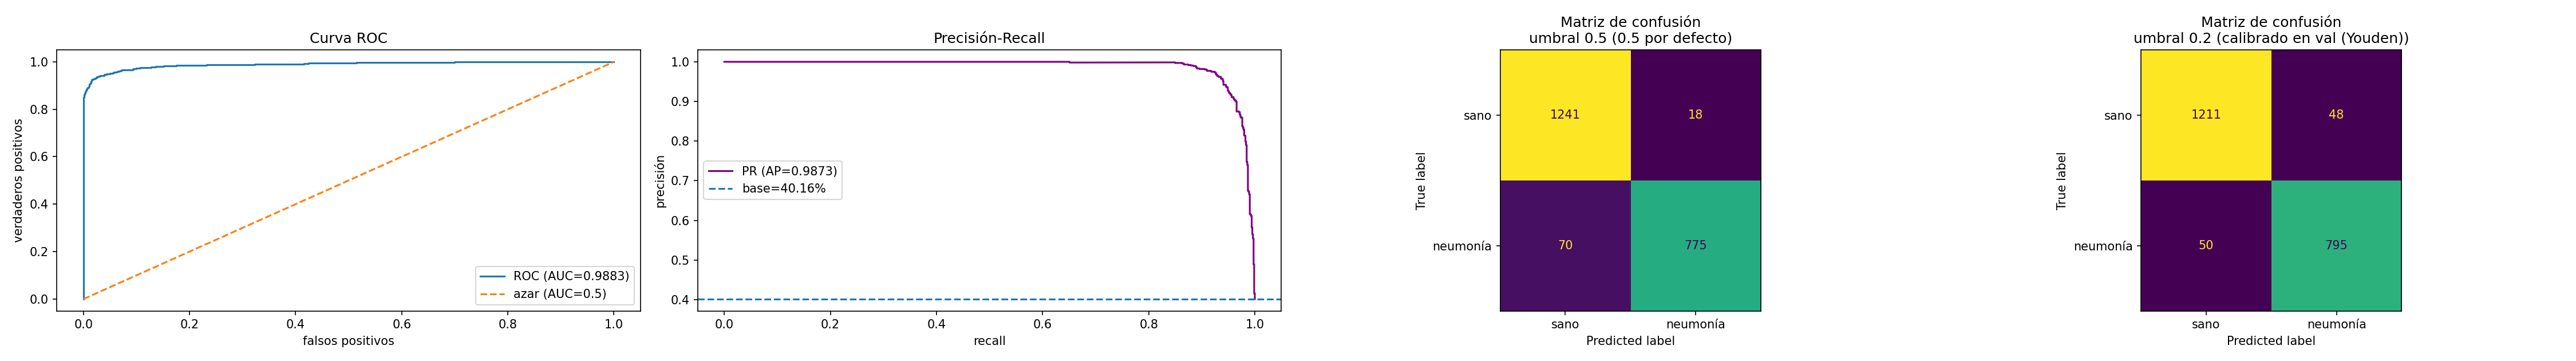

In [22]:
# Bloque 5.1 — Curvas ROC, precisión-recall y matrices de confusión (un panel por umbral)
# El AUC y el AP no dependen del umbral; las matrices si. Se muestran juntas para poder comparar.
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from IPython.display import Image as MostrarImagen, display

fpr, tpr, _ = roc_curve(reales, probs)  # ROC: qué tan bien separa sanos de enfermos
prec_c, rec_c, _ = precision_recall_curve(reales, probs)  # PR: útil con clases desbalanceadas
ap = float(average_precision_score(reales, probs))

fig, ax = plt.subplots(1, 2 + len(RESULTADOS_UMBRAL),
                       figsize=(7.5 * (2 + len(RESULTADOS_UMBRAL)), 4.2))
ax[0].plot(fpr, tpr, label=f'ROC (AUC={auc:.4f})')
ax[0].plot([0, 1], [0, 1], '--', label='azar (AUC=0.5)')
ax[0].set_title('Curva ROC')
ax[0].set_xlabel('falsos positivos')
ax[0].set_ylabel('verdaderos positivos')
ax[0].legend()
ax[1].plot(rec_c, prec_c, label=f'PR (AP={ap:.4f})', color='purple')
ax[1].axhline(reales.mean(), linestyle='--', label=f'base={reales.mean():.2%}')
ax[1].set_title('Precisión-Recall')
ax[1].set_xlabel('recall')
ax[1].set_ylabel('precisión')
ax[1].legend()
for _eje, (_u, _r) in zip(ax[2:], RESULTADOS_UMBRAL.items()):
    _p = (probs >= _u).astype(int)
    ConfusionMatrixDisplay.from_predictions(reales, _p, display_labels=['sano', 'neumonía'],
                                           ax=_eje, colorbar=False, values_format='d')
    _eje.set_title(f"Matriz de confusión\numbral {_u} ({_r['etiqueta']})")
fig.tight_layout()
RUTA_CURVAS_EVAL = CARPETA_CORRIDA / 'curvas_eval.png'
fig.savefig(RUTA_CURVAS_EVAL, dpi=150)
plt.close(fig)
print(f'AUC={auc:.4f} | AP={ap:.4f} (los mismos con cualquier umbral)')
print('Guardada en:', RUTA_CURVAS_EVAL)
display(MostrarImagen(str(RUTA_CURVAS_EVAL)))

In [23]:
# Bloque 5.2 — Métricas extendidas por umbral: precisión, recall, F1 y reporte por clase
# No recalcula nada: lee RESULTADOS_UMBRAL (bloque 4.1t) y solo añade el desglose por clase.
from sklearn.metrics import classification_report
import json as _json

ext = {'auc_roc': round(float(auc), 4), 'average_precision': round(float(ap), 4),
       'n_test': int(len(reales)), 'resultados_por_umbral': {}}
for _u, _r in RESULTADOS_UMBRAL.items():
    _p = (probs >= _u).astype(int)
    print(f"\n===== UMBRAL {_u} ({_r['etiqueta']}) =====")
    print(f"Precisión={_r['precision']:.4f} | Recall={_r['sensibilidad']:.4f} | "
          f"F1={_r['f1']:.4f} | Especificidad={_r['especificidad']:.4f} | "
          f"Exactitud={_r['exactitud']:.4f}")
    print(classification_report(reales, _p, target_names=['sano (0)', 'neumonía (1)'], digits=4))
    ext['resultados_por_umbral'][str(_u)] = {
        k: (round(v, 4) if isinstance(v, float) else v) for k, v in _r.items()}
with open(CARPETA_CORRIDA / 'metricas_extendidas.json', 'w') as f:
    _json.dump(ext, f, indent=2, ensure_ascii=False)
print('Guardadas en:', CARPETA_CORRIDA / 'metricas_extendidas.json')


===== UMBRAL 0.5 (0.5 por defecto) =====
Precisión=0.9773 | Recall=0.9172 | F1=0.9463 | Especificidad=0.9857 | Exactitud=0.9582
              precision    recall  f1-score   support

    sano (0)     0.9466    0.9857    0.9658      1259
neumonía (1)     0.9773    0.9172    0.9463       845

    accuracy                         0.9582      2104
   macro avg     0.9620    0.9514    0.9560      2104
weighted avg     0.9589    0.9582    0.9579      2104


===== UMBRAL 0.2 (calibrado en val (Youden)) =====
Precisión=0.9431 | Recall=0.9408 | F1=0.9419 | Especificidad=0.9619 | Exactitud=0.9534
              precision    recall  f1-score   support

    sano (0)     0.9603    0.9619    0.9611      1259
neumonía (1)     0.9431    0.9408    0.9419       845

    accuracy                         0.9534      2104
   macro avg     0.9517    0.9514    0.9515      2104
weighted avg     0.9534    0.9534    0.9534      2104

Guardadas en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20261013_040

Aciertos en la muestra: 6/6 (aciertos en los dos umbrales)

#  paciente  real      pred. u=0.5  pred. u=calib.  prob.  resultado
1  9f51baeb  sano      sano         sano            0%     ✓ acierto
2  b2c534fd  sano      sano         sano            0%     ✓ acierto
3  e314d288  sano      sano         sano            2%     ✓ acierto
4  f125b9c8  neumonía  neumonía     neumonía        100%   ✓ acierto
5  a887251c  neumonía  neumonía     neumonía        100%   ✓ acierto
6  bfd795ae  neumonía  neumonía     neumonía        100%   ✓ acierto
Guardada en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20261013_040954_auc986/casos_azar.png


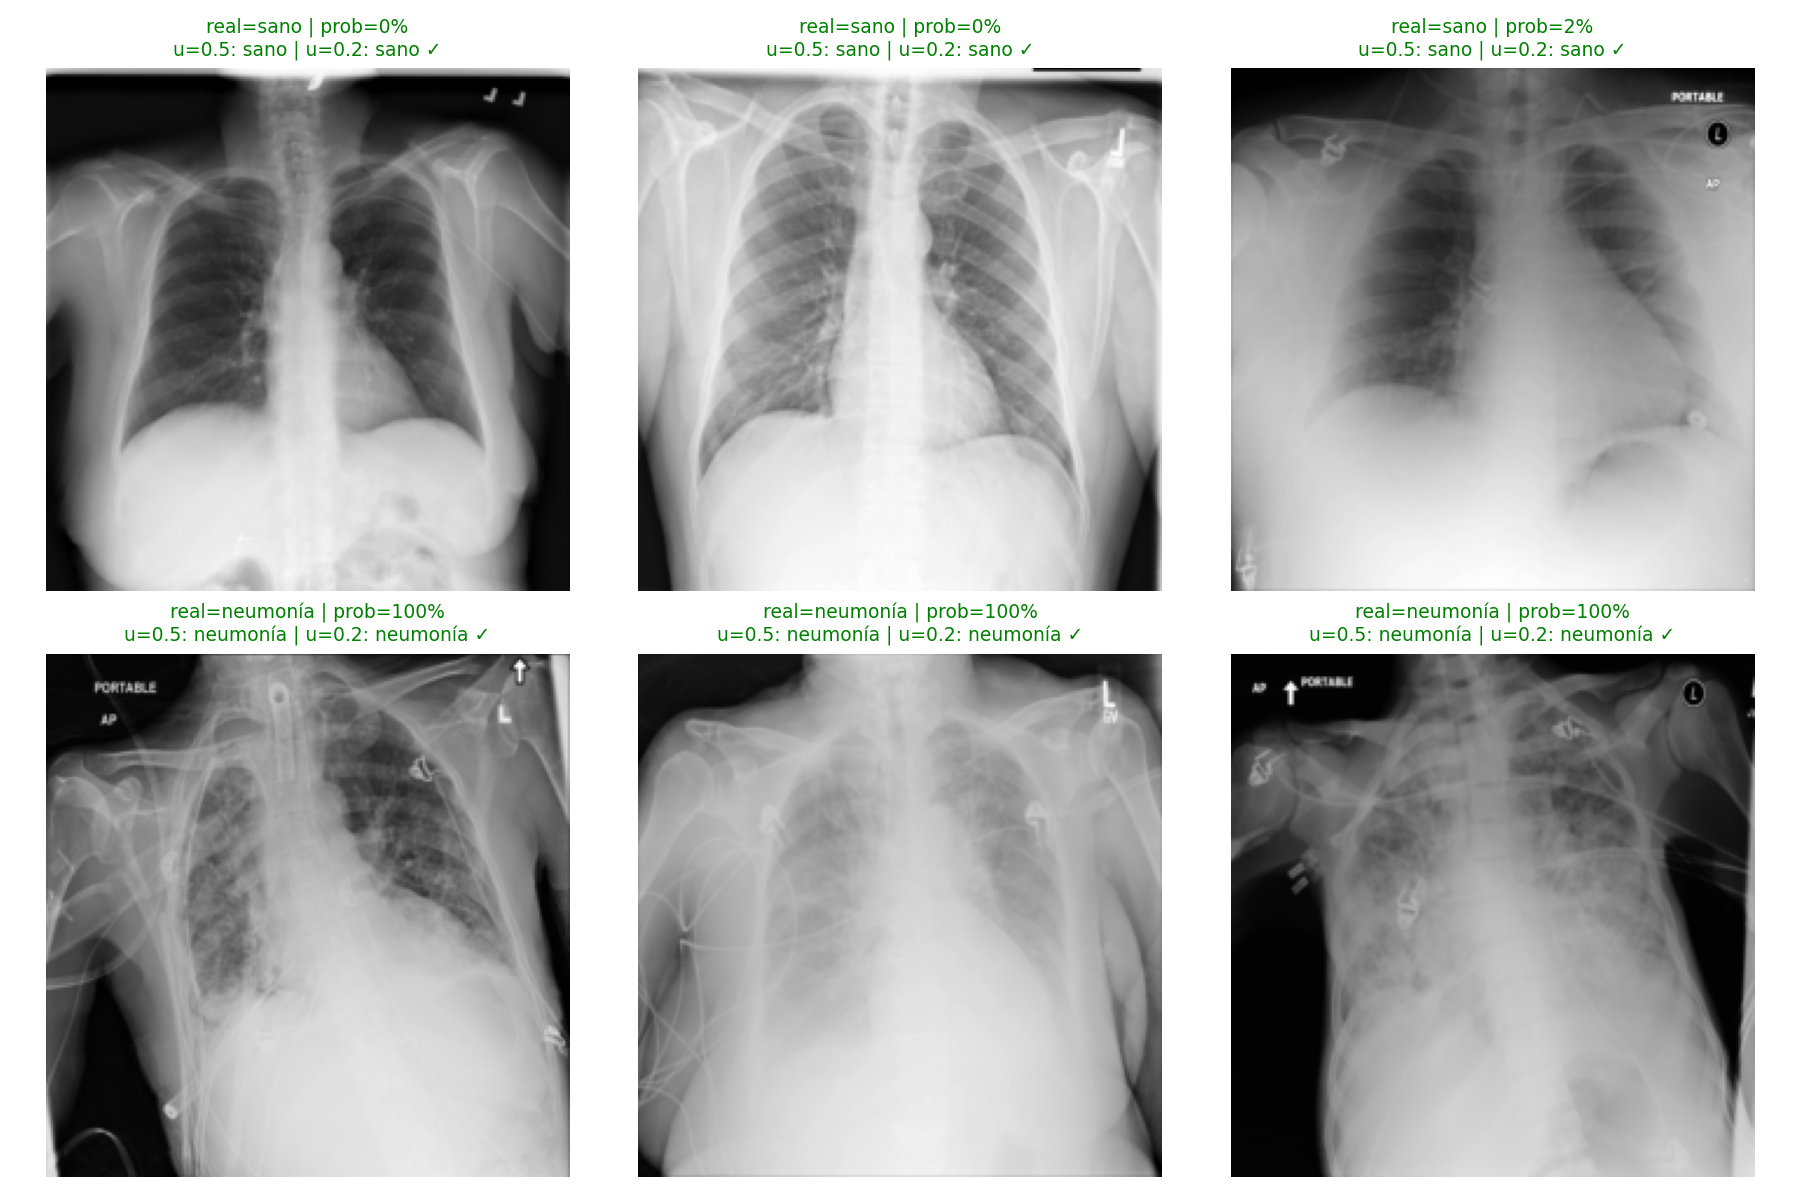

In [24]:
# Bloque 5.3 — Prueba con 6 pacientes al azar: ¿detecta bien?
# Cada placa muestra la predicción con los dos umbrales reportados (verde=acierto en ambos, rojo=falló alguno).
import matplotlib.pyplot as plt
from IPython.display import Image as MostrarImagen, display

def mostrar_gris(arr_norm):
    """Quita la normalización para ver la radiografía como gris 0-1."""
    img = arr_norm * DESV_IMAGENET[:, None, None] + MEDIA_IMAGENET[:, None, None]
    return np.clip(img[0], 0, 1)

rng = np.random.default_rng(7)  # semilla fija: siempre salen los mismos 6
idxs = rng.choice(len(df_test), size=6, replace=False)
_u_defecto = float(UMBRAL)
_u_calib = float(u_youden)
filas = []
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.ravel(), idxs):
    pid = df_test.iloc[i]['patientId']
    arr = np.load(CARPETA_NPY / 'test' / f'{pid}.npy')
    ax.imshow(mostrar_gris(arr), cmap='gray')
    ax.axis('off')
    r, p = int(reales[i]), float(probs[i])
    pp_def, pp_cal = bool(p >= _u_defecto), bool(p >= _u_calib)
    bien = (pp_def == bool(r)) and (pp_cal == bool(r))
    filas.append((pid[:8], r, pp_def, pp_cal, p, bien))
    ax.set_title(f"real={'neumonía' if r else 'sano'} | prob={p:.0%}\n"
                 f"u={_u_defecto}: {'neumonía' if pp_def else 'sano'} | "
                 f"u={_u_calib}: {'neumonía' if pp_cal else 'sano'} {'✓' if bien else '✗'}",
                 color='green' if bien else 'red', fontsize=9)
fig.tight_layout()
RUTA_CASOS = CARPETA_CORRIDA / 'casos_azar.png'
fig.savefig(RUTA_CASOS, dpi=150)
plt.close(fig)
print(f'Aciertos en la muestra: {int(sum(f[5] for f in filas))}/6 (aciertos en los dos umbrales)')
print(f"\n{'#':<3}{'paciente':<10}{'real':<10}{'pred. u=0.5':<13}{'pred. u=calib.':<16}{'prob.':<7}resultado")
for k, (corto, r, pd_, pc_, p, bien) in enumerate(filas, 1):
    print(f"{k:<3}{corto:<10}{'neumonía' if r else 'sano':<10}"
          f"{'neumonía' if pd_ else 'sano':<13}{'neumonía' if pc_ else 'sano':<16}"
          f"{p:<7.0%}{'✓ acierto' if bien else '✗ fallo'}")
print('Guardada en:', RUTA_CASOS)
display(MostrarImagen(str(RUTA_CASOS)))

In [25]:
# Bloque 5.4 — Tabla resumen final: todas las métricas en un cuadro, una columna por umbral
# No calcula nada nuevo: solo junta lo ya medido en 4.1 y 4.1t para copiar a la tesis.
from IPython.display import display  # aquí se muestra la tabla
import json as _json54  # aquí se guarda el JSON final

_independiente = {'AUC ROC': round(float(auc), 4),
                  'AP (área bajo PR)': round(float(ap), 4)}  # no dependen del umbral
_filas_resumen = [
    ('Exactitud (accuracy)', 'exactitud', 4),
    ('AUC ROC', None, 4),
    ('AP (área bajo PR)', None, 4),
    ('Sensibilidad (= recall)', 'sensibilidad', 4),
    ('Especificidad', 'especificidad', 4),
    ('Precisión', 'precision', 4),
    ('F1', 'f1', 4),
    ('TN (sanos bien)', 'tn', 0),
    ('FP (falsas alarmas)', 'fp', 0),
    ('FN (casos perdidos)', 'fn', 0),
    ('TP (detectados)', 'tp', 0),
    ('n test', None, 0),
    ('Errores límite (margen < 0.15)', 'errores_limite_margen015', 0),
]
_df_res = {'Métrica': [f[0] for f in _filas_resumen]}
for _u, _r in RESULTADOS_UMBRAL.items():
    _col = []
    for _nombre, _clave, _dec in _filas_resumen:
        if _nombre == 'n test':
            _col.append(int(len(reales)))
        elif _nombre in _independiente:
            _col.append(_independiente[_nombre])
        else:
            _col.append(round(_r[_clave], _dec) if _dec else int(_r[_clave]))
    _df_res[f"umbral {_u} ({_r['etiqueta']})"] = _col
df_resumen = pd.DataFrame(_df_res)
display(df_resumen)

# Se guarda junto al resto de la corrida (evidencia para la tesis).
df_resumen.to_csv(CARPETA_CORRIDA / 'tabla_resumen.csv', index=False)
final = {'modelo': 'densenet121_v2', 'corrida': RUN_ID, 'epocas': EPOCAS, 'lr': LR, 'batch': BATCH,
         'semilla': SEMILLA, 'mejor_auc_val': round(float(mejor_auc), 4),
         'n_test': int(len(reales)), 'resultados_por_umbral': RESULTADOS_UMBRAL}
with open(CARPETA_CORRIDA / 'metricas_final.json', 'w') as f:
    _json54.dump(final, f, indent=2, ensure_ascii=False)
print('Guardado en:', CARPETA_CORRIDA / 'tabla_resumen.csv', 'y metricas_final.json')

,Métrica,umbral 0.5 (0.5 por defecto),umbral 0.2 (calibrado en val (Youden))
0,Exactitud (accuracy),0.9582,0.9534
1,AUC ROC,0.9883,0.9883
2,AP (área bajo PR),0.9873,0.9873
3,Sensibilidad (= recall),0.9172,0.9408
4,Especificidad,0.9857,0.9619
5,Precisión,0.9773,0.9431
6,F1,0.9463,0.9419
7,TN (sanos bien),1241.0000,1211.0000
8,FP (falsas alarmas),18.0000,48.0000
9,FN (casos perdidos),70.0000,50.0000


Guardado en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20261013_040954_auc986/tabla_resumen.csv y metricas_final.json


In [26]:
# Bloque 5.5 — Costo computacional: qué tan caro es (no qué tan bien clasifica)
# El rendimiento ya quedó en 5.4. Aquí solo costo: parámetros, peso del .pth y velocidad.
# OJO: el tiempo por época solo se imprimió en la consola del 3.2 (no quedó en historial.csv).
# Para ESTA corrida cópialo de la salida; desde la próxima corrida se guarda solo.
import time as _time55  # aquí se cronometra la inferencia
from IPython.display import display as _mostrar55  # aquí se muestra la tabla
import json as _json55  # aquí se guarda el JSON de costo

try:
    n_params55 = int(n_params)  # ya contado en 2.1
except NameError:
    n_params55 = int(sum(p.numel() for p in modelo.parameters() if p.requires_grad))
tam_mb55 = RUTA_MEJOR.stat().st_size / 1e6 if RUTA_MEJOR.exists() else float('nan')
gpu55 = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'

# Velocidad de inferencia: 1 pasada completa al test, sin corregir, midiendo tiempo real.
# Incluye la carga de datos (es el costo de punta a punta). En GPU se sincroniza para medir bien.
modelo.eval()
lote0, _ = next(iter(cargar_test))
lote0 = lote0.to(device)
with torch.no_grad():
    for _ in range(5):  # calentamiento: la primera pasada siempre es más lenta
        _ = modelo(lote0)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_ini55 = _time55.perf_counter()
    n_imgs55 = 0
    for imagenes, _et in cargar_test:
        imagenes = imagenes.to(device)
        _ = modelo(imagenes)
        n_imgs55 += imagenes.size(0)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t_fin55 = _time55.perf_counter()
ms_img55 = (t_fin55 - t_ini55) / max(n_imgs55, 1) * 1000.0

costo = [
    ('Parámetros entrenables', n_params55),
    ('Peso best.pth (MB)', round(float(tam_mb55), 2)),
    ('GPU / dispositivo', f'{gpu55} ({device})'),
    ('Test medido (imágenes)', int(n_imgs55)),
    ('ms por imagen (inferencia)', round(float(ms_img55), 2)),
    ('imágenes por segundo', round(1000.0 / float(ms_img55), 1) if ms_img55 > 0 else None),
]

df_costo = pd.DataFrame(costo, columns=['Costo', 'Valor'])
_mostrar55(df_costo)

# Se guarda junto al resto de la corrida (evidencia para la tesis).
df_costo.to_csv(CARPETA_CORRIDA / 'tabla_costo.csv', index=False)
with open(CARPETA_CORRIDA / 'metricas_costo.json', 'w') as f:
    _json55.dump({k: v for k, v in costo}, f, indent=2, ensure_ascii=False)
print('Guardado en:', CARPETA_CORRIDA / 'tabla_costo.csv', 'y metricas_costo.json')


,Costo,Valor
0,Parámetros entrenables,6954881
1,Peso best.pth (MB),28.38
2,GPU / dispositivo,Tesla T4 (cuda)
3,Test medido (imágenes),2104
4,ms por imagen (inferencia),3.4
5,imágenes por segundo,293.7


Guardado en: /content/drive/MyDrive/TESIS/MODELOS/densenet121_v2_20261013_040954_auc986/tabla_costo.csv y metricas_costo.json


Umbral 0.5 (0.5 por defecto): FP=18 | FN=70 | errores límite (margen<0.15): 15 de 88
Umbral 0.2 (calibrado en val (Youden)): FP=48 | FN=50 | errores límite (margen<0.15): 40 de 98

 umbral tipo paciente     real predicho  prob  margen lectura
    0.5   FP ded4a0d9     sano neumonía  1.00    0.50  seguro
    0.5   FP d1f7a9ef     sano neumonía  0.92    0.42  seguro
    0.5   FP b7f3190f     sano neumonía  0.90    0.40  seguro
    0.5   FN 05744f1d neumonía     sano  0.00    0.50  seguro
    0.5   FN 5dd4d7bf neumonía     sano  0.00    0.50  seguro
    0.5   FN b2ea9c20 neumonía     sano  0.00    0.50  seguro
    0.2   FP ded4a0d9     sano neumonía  1.00    0.80  seguro
    0.2   FP d1f7a9ef     sano neumonía  0.92    0.72  seguro
    0.2   FP b7f3190f     sano neumonía  0.90    0.70  seguro
    0.2   FN 05744f1d neumonía     sano  0.00    0.20  seguro
    0.2   FN 5dd4d7bf neumonía     sano  0.00    0.20  seguro
    0.2   FN b2ea9c20 neumonía     sano  0.00    0.20  seguro
Guardado en: 

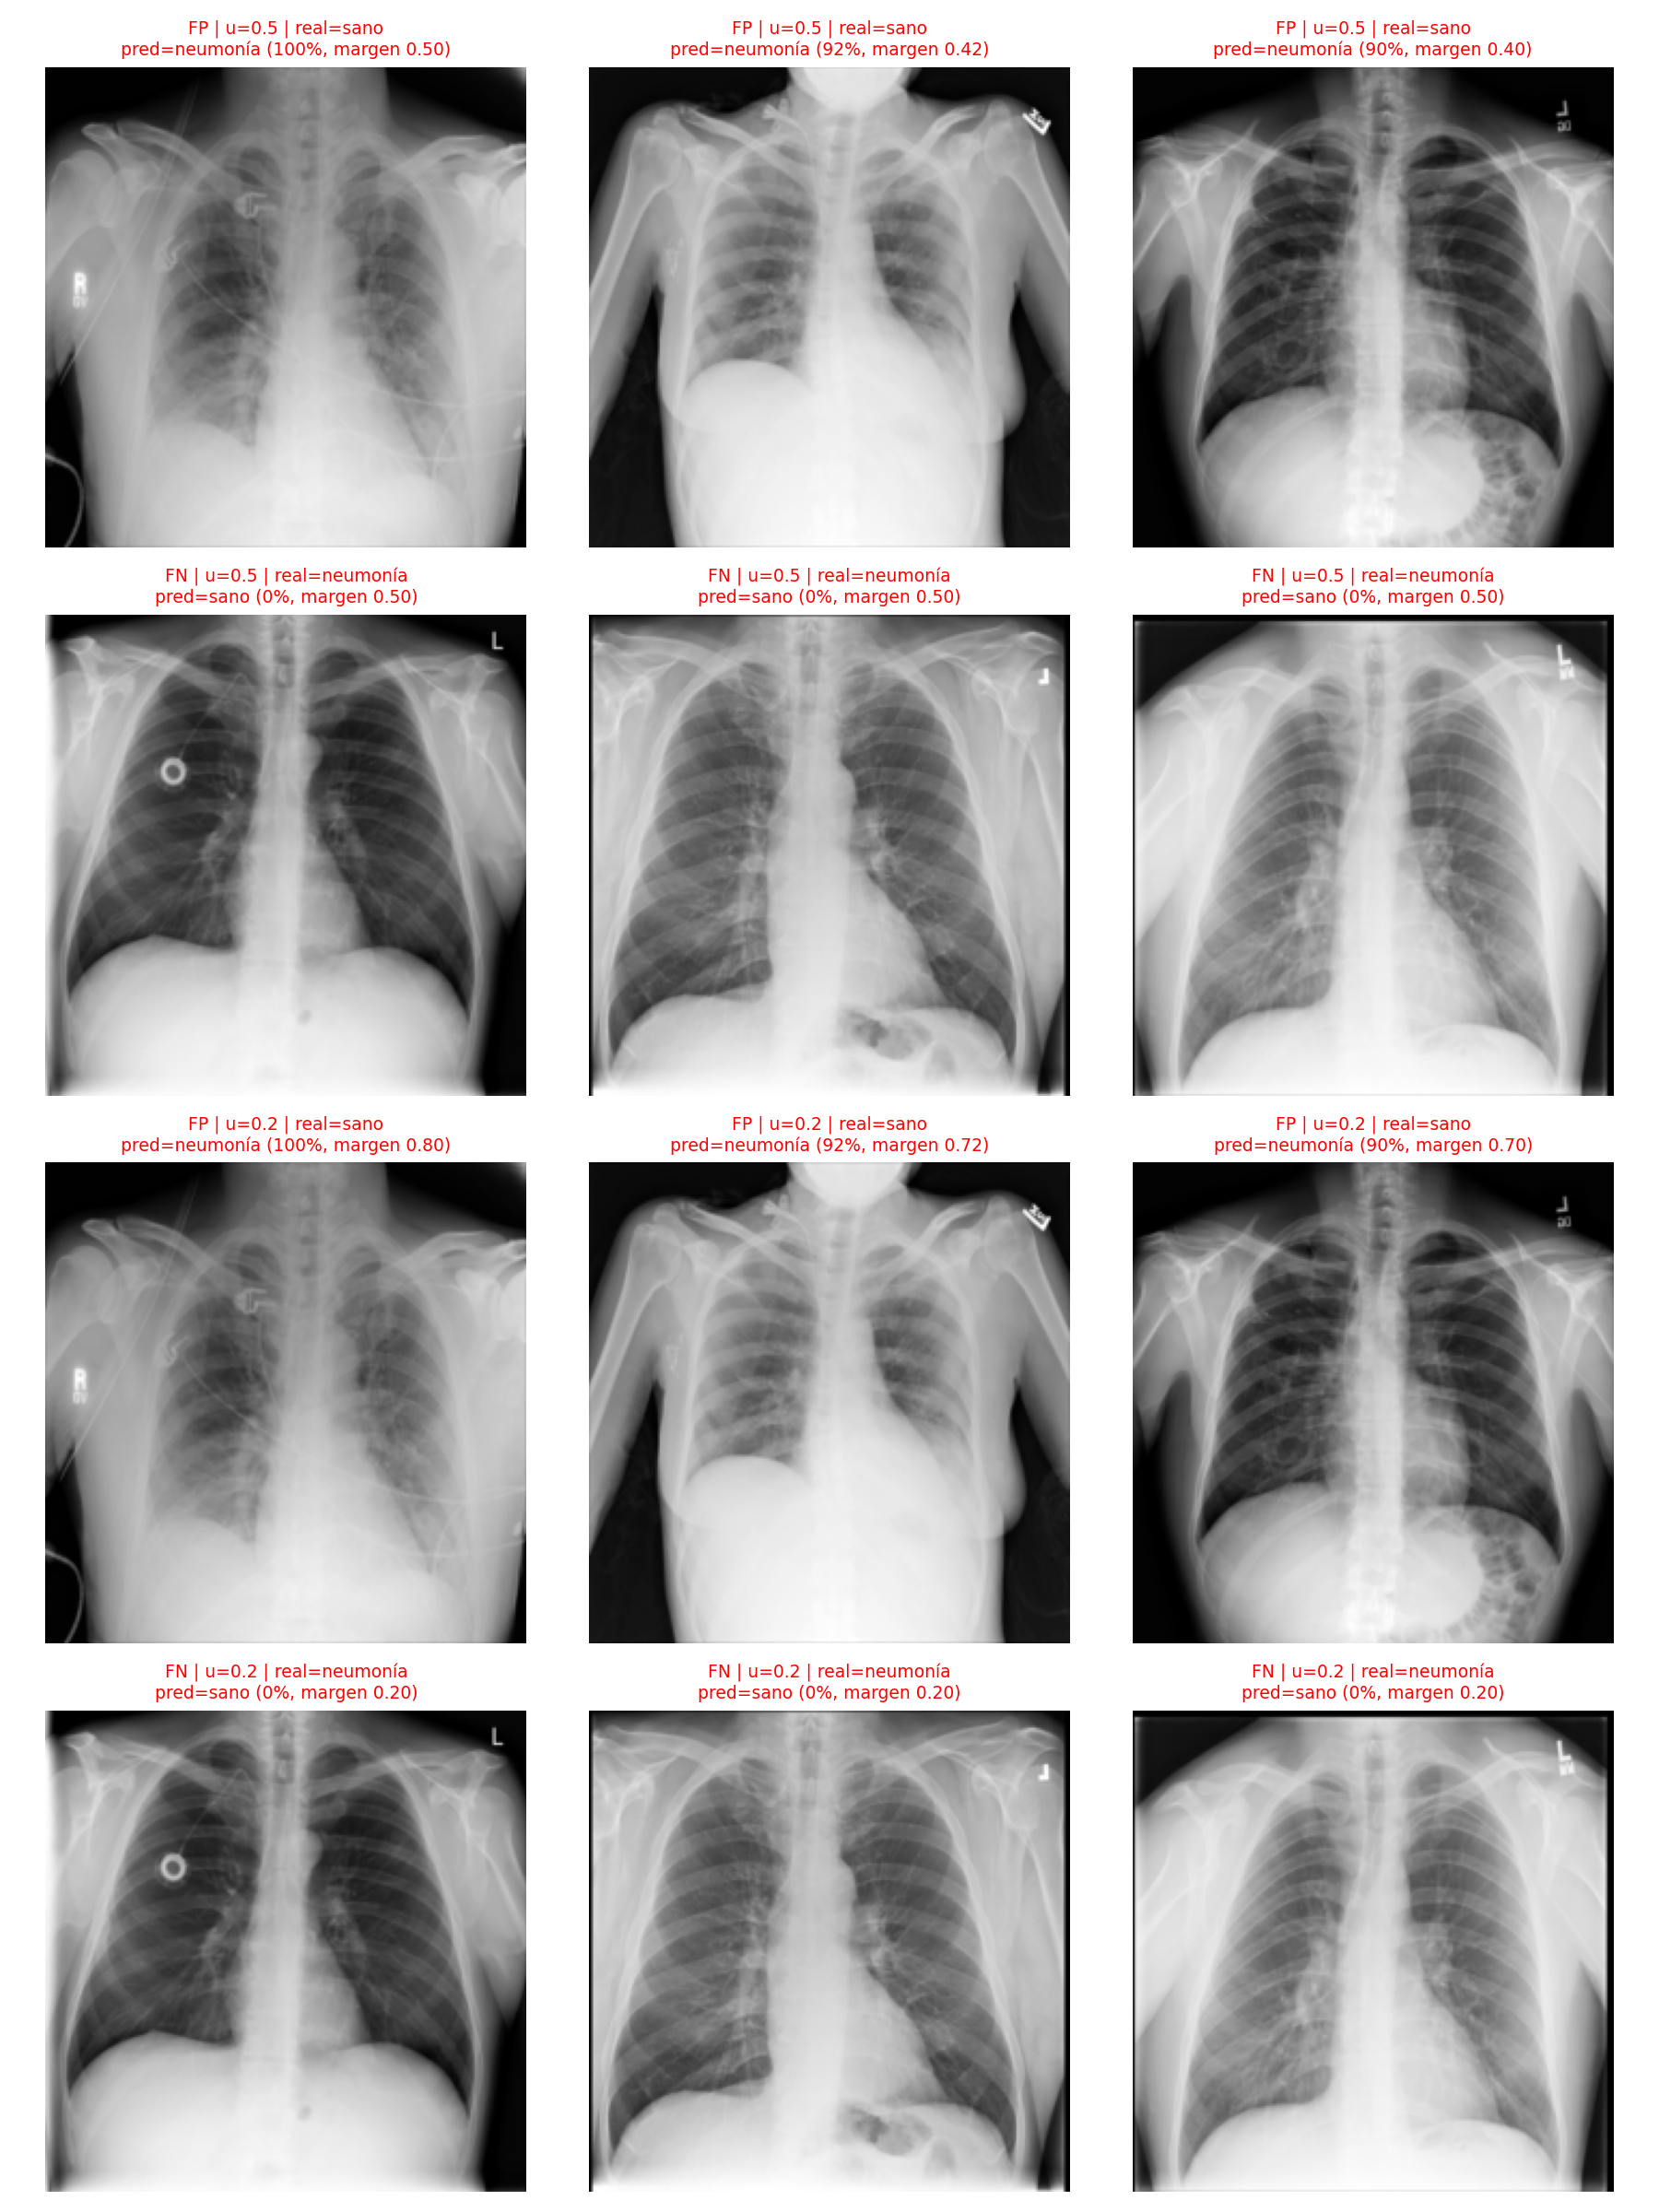

In [27]:
# Bloque 5.6 — Galería de errores: FP y FN con imagen, para CADA umbral reportado
# No mide nada nuevo: muestra los 3 falsos positivos y los 3 falsos negativos más seguros
# (los que más se alejaron del umbral) de cada umbral.
# Lectura: margen chico = caso límite razonable; margen grande = falla con alta confianza.
import matplotlib.pyplot as plt
from IPython.display import Image as MostrarImagen56, display as _mostrar56


def _gris56(arr_norm):
    """Quita la normalización para ver la radiografía como gris 0-1."""
    img = arr_norm * DESV_IMAGENET[:, None, None] + MEDIA_IMAGENET[:, None, None]
    return np.clip(img[0], 0, 1)


_bloques56 = []
for _u, _r in RESULTADOS_UMBRAL.items():
    _pred56 = (probs >= _u).astype(int)
    _idx_fp56 = np.where((_pred56 == 1) & (reales == 0))[0]
    _idx_fn56 = np.where((_pred56 == 0) & (reales == 1))[0]
    _idx_fp56 = _idx_fp56[np.argsort(-probs[_idx_fp56])][:3]  # falsas alarmas más seguras primero
    _idx_fn56 = _idx_fn56[np.argsort(probs[_idx_fn56])][:3]  # perdidos más seguros primero
    _bloques56.append((_u, _r, _idx_fp56, _idx_fn56))
    print(f"Umbral {_u} ({_r['etiqueta']}): FP={_r['fp']} | FN={_r['fn']} | "
          f"errores límite (margen<0.15): {_r['errores_limite_margen015']} de {_r['errores_totales']}")

filas56 = []  # tabla descriptiva (se imprime y se guarda)
fig56, ejes56 = plt.subplots(2 * len(_bloques56), 3, figsize=(12, 8 * len(_bloques56)))
for _fila, (_u, _r, _idx_fp56, _idx_fn56) in enumerate(_bloques56):
    for _sub, (_tipo, _idxs) in enumerate([('FP', _idx_fp56), ('FN', _idx_fn56)]):
        for _ax, _i in zip(ejes56[2 * _fila + _sub], _idxs):
            _pid = df_test.iloc[int(_i)]['patientId']
            _arr = np.load(CARPETA_NPY / 'test' / f'{_pid}.npy')
            _ax.imshow(_gris56(_arr), cmap='gray')
            _ax.axis('off')
            _real, _prob = int(reales[_i]), float(probs[_i])
            _m = abs(_prob - float(_u))
            _lectura = 'límite' if _m < 0.15 else 'seguro'
            _predicho = 'neumonía' if _prob >= _u else 'sano'
            filas56.append((round(float(_u), 2), _tipo, _pid[:8],
                            'neumonía' if _real else 'sano', _predicho,
                            round(_prob, 2), round(_m, 2), _lectura))
            _ax.set_title(f"{_tipo} | u={_u} | real={'neumonía' if _real else 'sano'}\n"
                          f"pred={_predicho} ({_prob:.0%}, margen {_m:.2f})",
                          color='red', fontsize=9)
fig56.tight_layout()
RUTA_ERRORES = CARPETA_CORRIDA / 'casos_error.png'
fig56.savefig(RUTA_ERRORES, dpi=150)
plt.close(fig56)
df_err56 = pd.DataFrame(filas56, columns=['umbral', 'tipo', 'paciente', 'real', 'predicho',
                                          'prob', 'margen', 'lectura'])
df_err56.to_csv(CARPETA_CORRIDA / 'tabla_errores.csv', index=False)
print()
print(df_err56.to_string(index=False))
print('Guardado en:', RUTA_ERRORES, 'y tabla_errores.csv')
_mostrar56(MostrarImagen56(str(RUTA_ERRORES)))